<a href="https://colab.research.google.com/github/Fayaz2010/Artificial-Intelligence-Project/blob/main/CSE422_Student_Depression_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# CSE422 Machine Learning Project

## Student Depression Level Prediction Using Machine Learning

**Target Feature:** Depression Label

**Machine Learning Tasks:**
- Supervised Learning: Classification
- Unsupervised Learning: K-Means Clustering

### Aim
The aim of this project is to predict students' depression levels using demographic, academic, anxiety, and stress-related factors. The model can help identify patterns associated with student mental health conditions.


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving 13.csv to 13 (1).csv


In [ ]:

# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, auc
)

from sklearn.multiclass import OneVsRestClassifier

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout


In [ ]:

# Load Dataset

df = pd.read_csv('13.csv')

print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (1977, 37)


,1. Age,2. Gender,5. Academic Year,6. Current CGPA,7. Did you receive a waiver or scholarship at your university?,"1. In a semester, how often you felt nervous, anxious or on edge due to academic pressure?","2. In a semester, how often have you been unable to stop worrying about your academic affairs?","3. In a semester, how often have you had trouble relaxing due to academic pressure?","4. In a semester, how often have you been easily annoyed or irritated because of academic pressure?","5. In a semester, how often have you worried too much about academic affairs?",...,"2. In a semester, how often have you been feeling down, depressed or hopeless?","3. In a semester, how often have you had trouble falling or staying asleep, or sleeping too much?","4. In a semester, how often have you been feeling tired or having little energy?","5. In a semester, how often have you had poor appetite or overeating?","6. In a semester, how often have you been feeling bad about yourself - or that you are a failure or have let yourself or your family down?","7. In a semester, how often have you been having trouble concentrating on things, such as reading the books or watching television?","8. In a semester, how often have you moved or spoke too slowly for other people to notice? Or you've been moving a lot more than usual because you've been restless?","9. In a semester, how often have you had thoughts that you would be better off dead, or of hurting yourself?",Depression Value,Depression Label
0,18-22,Female,Fourth Year or Equivalent,2.50 - 2.99,No,1,1,1,2,2,...,2,1,1,2,1,1,1,1,11,Moderate Depression
1,18-22,Male,First Year or Equivalent,3.80 - 4.00,No,2,2,1,1,1,...,1,1,1,1,1,1,1,1,9,Mild Depression
2,18-22,Male,First Year or Equivalent,3.00 - 3.39,No,2,1,1,0,2,...,0,2,3,2,2,2,2,1,16,Moderately Severe Depression
3,18-22,Male,First Year or Equivalent,3.40 - 3.79,No,2,1,1,1,1,...,1,1,1,1,1,1,1,1,9,Mild Depression
4,18-22,Male,First Year or Equivalent,3.40 - 3.79,No,1,1,1,1,1,...,1,1,1,1,1,1,1,1,9,Mild Depression



# Dataset Description

The dataset contains student mental health related information.

It includes:
- Demographic features
- Academic features
- Anxiety-related features
- Stress-related features
- Depression-related features

The target feature is Depression Label.


In [ ]:

# Checking Missing Values and Duplicates

print("Missing values:")
print(df.isnull().sum().sum())

print("Duplicate rows:")
print(df.duplicated().sum())

# Removing duplicates
df = df.drop_duplicates()

# Removing missing values
df = df.dropna()

print("Updated Shape:", df.shape)


Missing values:
6
Duplicate rows:
5
Updated Shape: (1966, 37)


In [ ]:

# Encoding Categorical Features

encoder = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = encoder.fit_transform(df[col])

df.head()


,1. Age,2. Gender,5. Academic Year,6. Current CGPA,7. Did you receive a waiver or scholarship at your university?,"1. In a semester, how often you felt nervous, anxious or on edge due to academic pressure?","2. In a semester, how often have you been unable to stop worrying about your academic affairs?","3. In a semester, how often have you had trouble relaxing due to academic pressure?","4. In a semester, how often have you been easily annoyed or irritated because of academic pressure?","5. In a semester, how often have you worried too much about academic affairs?",...,"2. In a semester, how often have you been feeling down, depressed or hopeless?","3. In a semester, how often have you had trouble falling or staying asleep, or sleeping too much?","4. In a semester, how often have you been feeling tired or having little energy?","5. In a semester, how often have you had poor appetite or overeating?","6. In a semester, how often have you been feeling bad about yourself - or that you are a failure or have let yourself or your family down?","7. In a semester, how often have you been having trouble concentrating on things, such as reading the books or watching television?","8. In a semester, how often have you moved or spoke too slowly for other people to notice? Or you've been moving a lot more than usual because you've been restless?","9. In a semester, how often have you had thoughts that you would be better off dead, or of hurting yourself?",Depression Value,Depression Label
0,0,0,1,0,0,1,1,1,2,2,...,2,1,1,2,1,1,1,1,11,2
1,0,1,0,3,0,2,2,1,1,1,...,1,1,1,1,1,1,1,1,9,0
2,0,1,0,1,0,2,1,1,0,2,...,0,2,3,2,2,2,2,1,16,3
3,0,1,0,2,0,2,1,1,1,1,...,1,1,1,1,1,1,1,1,9,0
4,0,1,0,2,0,1,1,1,1,1,...,1,1,1,1,1,1,1,1,9,0


In [ ]:

# Feature Selection and Scaling

target = 'Depression Label'

X = df.drop(target, axis=1)
y = df[target]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)


(1572, 36) (394, 36)


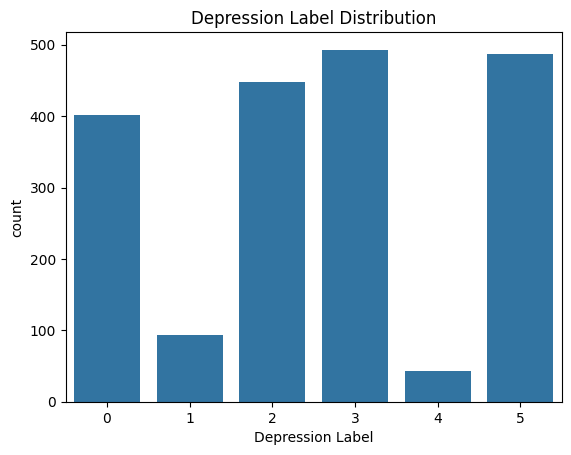

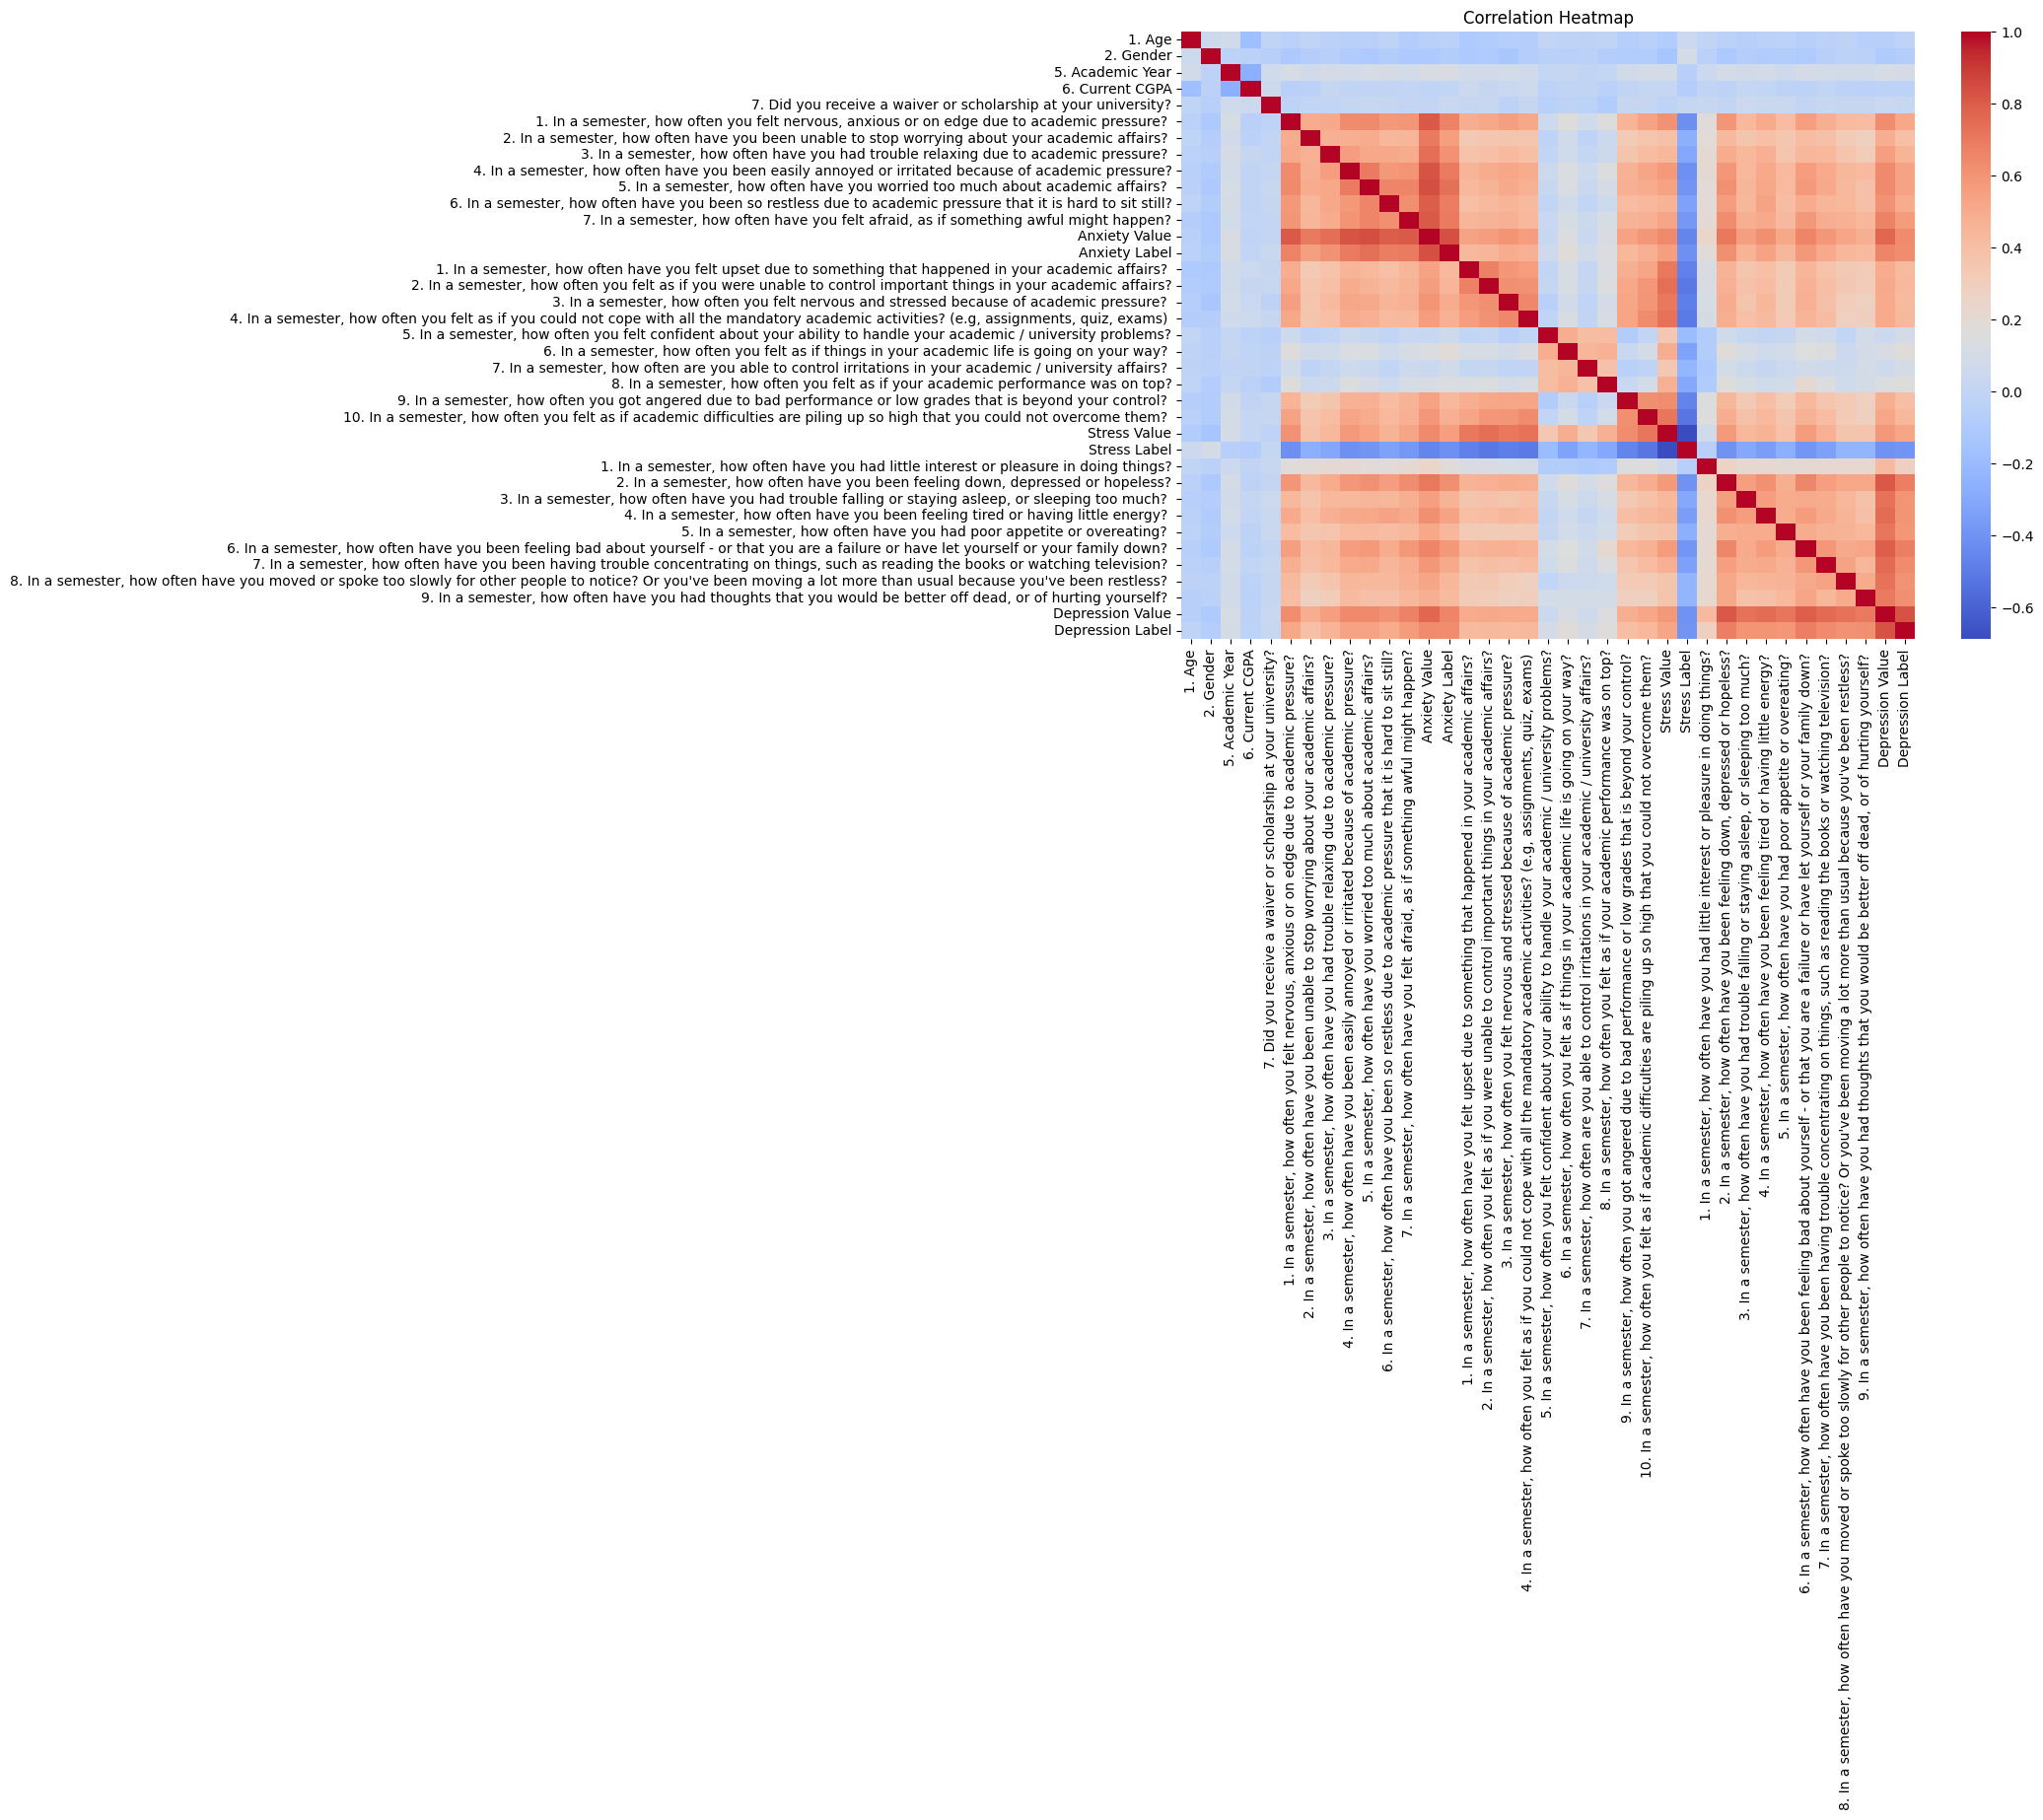

In [ ]:

# Exploratory Data Analysis

sns.countplot(x=df[target])
plt.title("Depression Label Distribution")
plt.show()

plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


In [ ]:

# Decision Tree Model

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)


In [ ]:

# KNN Model

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)


In [ ]:

# Neural Network Model

nn = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])

nn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

nn.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2
)

nn_pred = np.argmax(nn.predict(X_test), axis=1)


Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.3699 - loss: 1.5674 - val_accuracy: 0.4794 - val_loss: 1.3003
Epoch 2/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5529 - loss: 1.2048 - val_accuracy: 0.5810 - val_loss: 1.0676
Epoch 3/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6110 - loss: 1.0105 - val_accuracy: 0.6476 - val_loss: 0.9259
Epoch 4/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6587 - loss: 0.8920 - val_accuracy: 0.6825 - val_loss: 0.8189
Epoch 5/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7025 - loss: 0.7771 - val_accuracy: 0.7048 - val_loss: 0.7341
Epoch 6/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7303 - loss: 0.6921 - val_accuracy: 0.7587 - val_loss: 0.6507
Epoch 7/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7582 - loss: 0.6372 - val_accuracy: 0.7746 - val_loss: 0.5958
Epoch 8/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7979 - loss: 0.5802 - val_accuracy: 0.7873 - val_loss: 0.5428
Epo


 Decision Tree
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


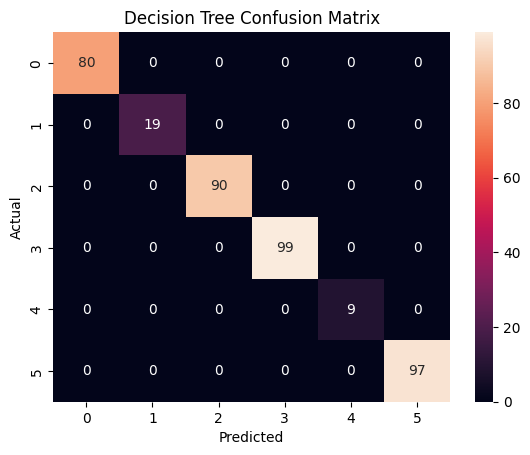


 KNN
Accuracy: 0.6979695431472082
Precision: 0.7163769133301525
Recall: 0.6979695431472082
F1 Score: 0.6886181092682394


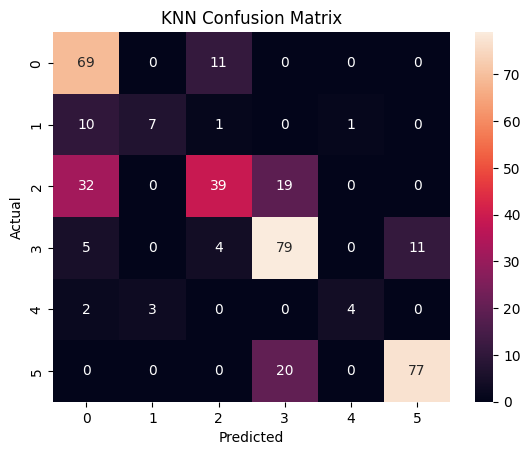


 Neural Network
Accuracy: 0.8984771573604061
Precision: 0.8990412426161246
Recall: 0.8984771573604061
F1 Score: 0.8911255158744962


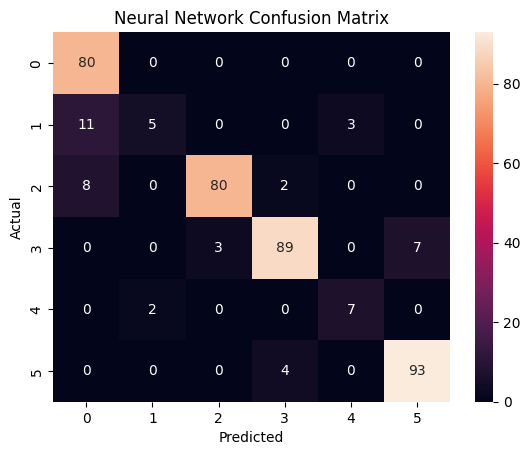

In [ ]:

# Model Evaluation Function

def evaluate_model(name, y_true, y_pred):
    print("\n", name)
    print("Accuracy:", accuracy_score(y_true,y_pred))
    print("Precision:", precision_score(y_true,y_pred,average='weighted'))
    print("Recall:", recall_score(y_true,y_pred,average='weighted'))
    print("F1 Score:", f1_score(y_true,y_pred,average='weighted'))

    cm = confusion_matrix(y_true,y_pred)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

evaluate_model("Decision Tree", y_test, dt_pred)
evaluate_model("KNN", y_test, knn_pred)
evaluate_model("Neural Network", y_test, nn_pred)


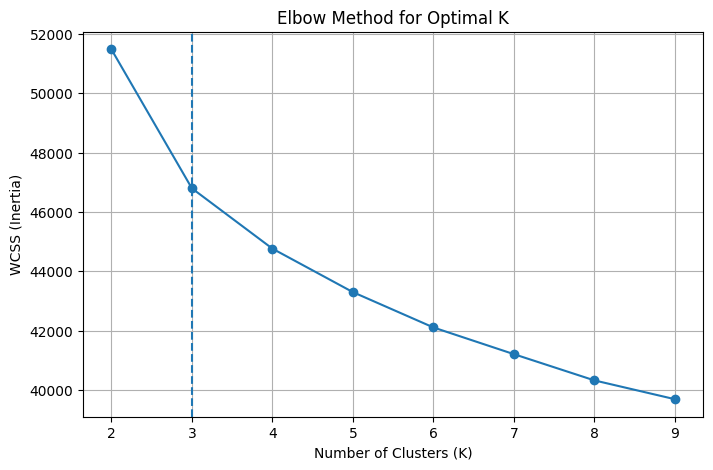

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Finding optimal clusters using Elbow Method

inertia = []

K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)


# Plot Elbow Curve

plt.figure(figsize=(8,5))

plt.plot(
    K_range,
    inertia,
    marker='o'
)

# Vertical line showing optimal K
plt.axvline(
    x=3,
    linestyle='--'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method for Optimal K")

plt.xticks(K_range)
plt.grid(True)

plt.show()

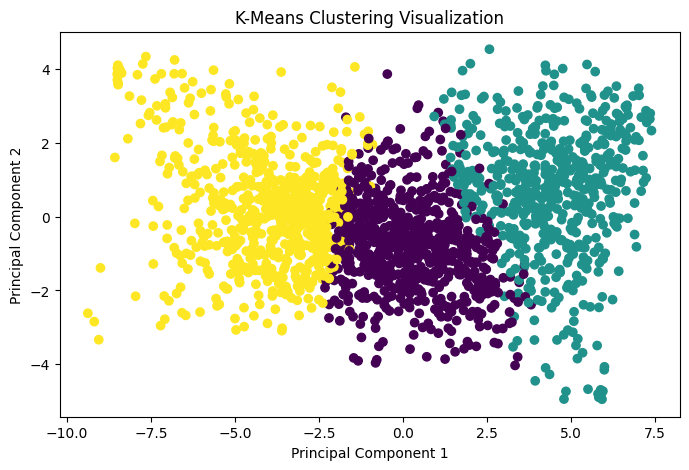

Silhouette Score: 0.13937019724417765


In [ ]:
# Apply K-Means

from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df['Cluster'] = clusters


# PCA for visualization

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)


plt.figure(figsize=(8,5))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=clusters
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering Visualization")

plt.show()


# Silhouette Score

score = silhouette_score(
    X_scaled,
    clusters
)

print("Silhouette Score:", score)


# Conclusion

The models are compared using:
- Accuracy
- Precision
- Recall
- F1 Score
- Confusion Matrix
- ROC Curve
- AUC Score

The best model is selected based on evaluation performance.

Possible reasons:
- Neural Network can learn complex relationships between multiple psychological factors.
- Decision Tree captures non-linear decision patterns.
- KNN performs based on similarity between students and requires proper scaling.
